In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline
from scipy.stats import shapiro, normaltest
from scipy import stats

In [2]:
medical_df = pd.read_csv('C:/Users/Ivanna/Documents/Dataset/medical-charges.csv')
medical_df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
medical_df.describe().round(2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


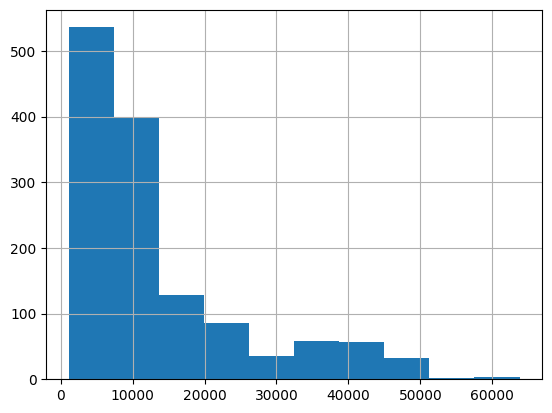

In [4]:
medical_df.charges.hist();

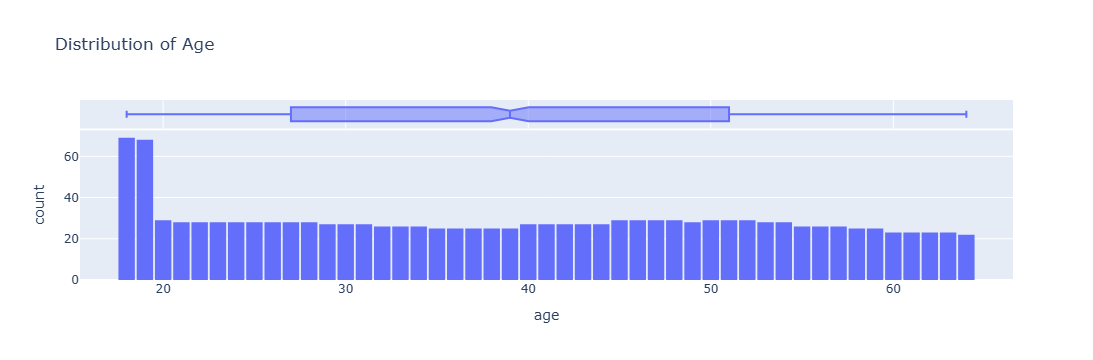

In [5]:
fig = px.histogram(medical_df,
                   x='age',
                   marginal='box',
                   nbins=47,
                   title='Distribution of Age')
fig.update_layout(bargap=0.1)
fig.show()

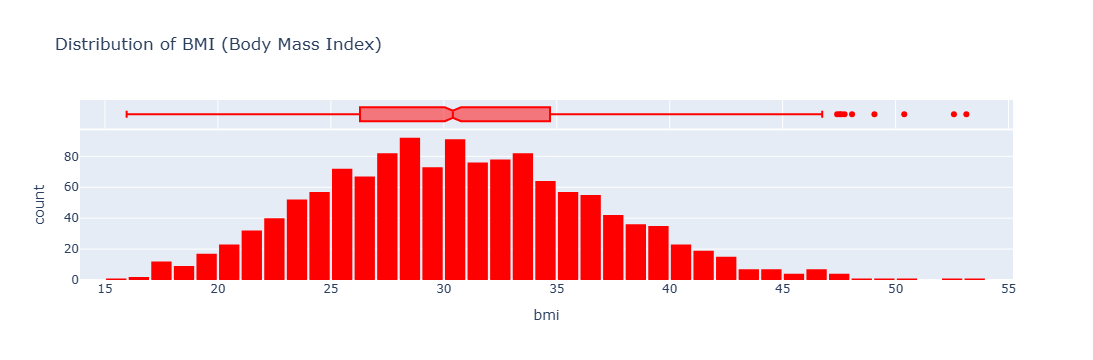

In [6]:
fig = px.histogram(medical_df,
                   x='bmi',
                   marginal='box',
                   color_discrete_sequence=['red'],
                   title='Distribution of BMI (Body Mass Index)')
fig.update_layout(bargap=0.1)
fig.show()

# Перевірка на нормальність

Один з поширених способів перевірити, чи є дані розподілені за Гаусом - це використання статистичних тестів, найчастіше викорситовують тест Shapiro–Wilk або тест D'Agostino's K-squared.

- Shapiro–Wilk Test ефективний для невеликих вибірок (менше 2000 спостережень) і часто використовується для перевірки нормальності.

- D'Agostino's K-squared Test базується на куртозисі та асиметрії ваших даних для перевірки нормальності. Він краще підходить для великих вибірок.

In [7]:
def analyze_normal(data_input, column_name=None, alpha=0.05):
    """Виконує аналіз даних на нормальність за допомогою тестів Шапіро-Вілка

    та Д'Агостіно.

    Parameters:
    -----------
    data_input : pandas.DataFrame, pandas.Series або array-like
        Вхідні дані для аналізу.
    column_name : str, optional
        Назва колонки, якщо у data_input передано DataFrame.
    alpha : float, default 0.05
        Рівень значущості для перевірки гіпотези H0.
    """

    if isinstance(data_input, pd.DataFrame):
        if column_name is None:
            raise ValueError(
                "Вкажіть 'column_name'."
            )
        series = data_input[column_name].dropna()
        title = column_name
    elif isinstance(data_input, pd.Series):
        series = data_input.dropna()
        title = series.name if series.name else "Передані дані"
    else:
        series = pd.Series(data_input).dropna()
        title = "Передані дані"

    print(f"АНАЛІЗ НА НОРМАЛЬНІСТЬ: '{title}'")
    print(f"Кількість спостережень: {len(series)}")
    print("H0: Дані мають нормальний розподіл.\n")

    # Shapiro–Wilk Test
    # (Примітка: Shapiro-Wilk найбільш коректний при N <= 5000)
    stat_shapiro, p_val_shapiro = shapiro(series)
    print("Shapiro–Wilk Test:")
    print(f"  Статистика тесту: {stat_shapiro}")
    print(f"  P-значення:       {p_val_shapiro}")

    if p_val_shapiro > alpha:
        print(
            f"  ✅ Дані мають нормальний розподіл (p > {alpha}, не відхиляємо H0)."
        )
    else:
        print(
            f"  ❌ Дані не мають нормального розподілу (p <= {alpha}, відхиляємо H0)."
        )

    # D'Agostino's K-squared Test
    stat_agostino, p_val_agostino = normaltest(series)
    print("\nD'Agostino's K-squared Test:")
    print(f"Статистика тесту: {stat_agostino}")
    print(f"P-значення:       {p_val_agostino}")

    if p_val_agostino > alpha:
        print(
            f"  ✅ Дані мають нормальний розподіл (p > {alpha}, не відхиляємо H0)."
        )
    else:
        print(
            f"  ❌ Дані не мають нормального розподілу (p <= {alpha}, відхиляємо H0)."
        )

In [8]:
analyze_normal(medical_df, 'bmi')

АНАЛІЗ НА НОРМАЛЬНІСТЬ: 'bmi'
Кількість спостережень: 1338
H0: Дані мають нормальний розподіл.

Shapiro–Wilk Test:
  Статистика тесту: 0.9938864621676107
  P-значення:       2.6046836879834408e-05
  ❌ Дані не мають нормального розподілу (p <= 0.05, відхиляємо H0).

D'Agostino's K-squared Test:
Статистика тесту: 17.581447872784118
P-значення:       0.0001521377897266011
  ❌ Дані не мають нормального розподілу (p <= 0.05, відхиляємо H0).


In [9]:
analyze_normal(medical_df, 'age')

АНАЛІЗ НА НОРМАЛЬНІСТЬ: 'age'
Кількість спостережень: 1338
H0: Дані мають нормальний розподіл.

Shapiro–Wilk Test:
  Статистика тесту: 0.9447009637825445
  P-значення:       5.69204692845418e-22
  ❌ Дані не мають нормального розподілу (p <= 0.05, відхиляємо H0).

D'Agostino's K-squared Test:
Статистика тесту: 1557.8205812363667
P-значення:       0.0
  ❌ Дані не мають нормального розподілу (p <= 0.05, відхиляємо H0).


In [10]:
analyze_normal(medical_df, 'charges')

АНАЛІЗ НА НОРМАЛЬНІСТЬ: 'charges'
Кількість спостережень: 1338
H0: Дані мають нормальний розподіл.

Shapiro–Wilk Test:
  Статистика тесту: 0.8146881157362383
  P-значення:       1.1505226334932036e-36
  ❌ Дані не мають нормального розподілу (p <= 0.05, відхиляємо H0).

D'Agostino's K-squared Test:
Статистика тесту: 336.8851220567733
P-значення:       7.019807901276197e-74
  ❌ Дані не мають нормального розподілу (p <= 0.05, відхиляємо H0).


# QQ-Plot

QQ-Plot — це графічний метод для визначення того, чи відповідає набір даних певному розподілу ймовірностей, чи дві вибірки даних надійшли з однієї сукупності чи ні.

- Це графік квантилів першого набору даних проти квантилів другого набору даних.

- Для довідкових цілей також наносять на графік лінію 45%; і якщо вибірки з однієї сукупності, то точки розташовані вздовж цієї лінії.

In [11]:
def plot_qq(data_input, column_name=None):
    """Будує окремий Q-Q графік для візуальної перевірки нормальності розподілу.

    Parameters:
    -----------
    data_input : pandas.DataFrame, pandas.Series або array-like
        Вхідні дані.
    column_name : str, optional
        Назва колонки, якщо у data_input передано DataFrame.
    """
    if isinstance(data_input, pd.DataFrame):
        if column_name is None:
            raise ValueError(
                "Вкажіть 'column_name'."
            )
        series = data_input[column_name].dropna()
        title = column_name
    elif isinstance(data_input, pd.Series):
        series = data_input.dropna()
        title = series.name if series.name else "Дані"
    else:
        series = pd.Series(data_input).dropna()
        title = "Дані"

    # Побудова графіка
    plt.figure(figsize=(7, 5))
    stats.probplot(series, dist="norm", plot=plt)
    plt.title(f"QQ-графік для перевірки нормальності: {title}")
    plt.xlabel("Теоретичні квантелі", fontsize=10)
    plt.ylabel("Фактичні значення", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

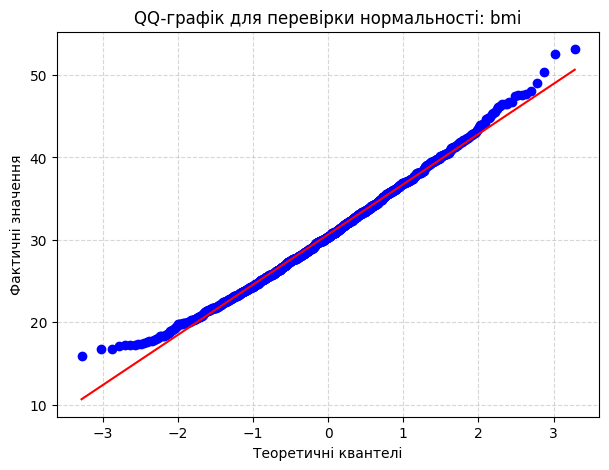

In [12]:
plot_qq(medical_df, 'bmi')

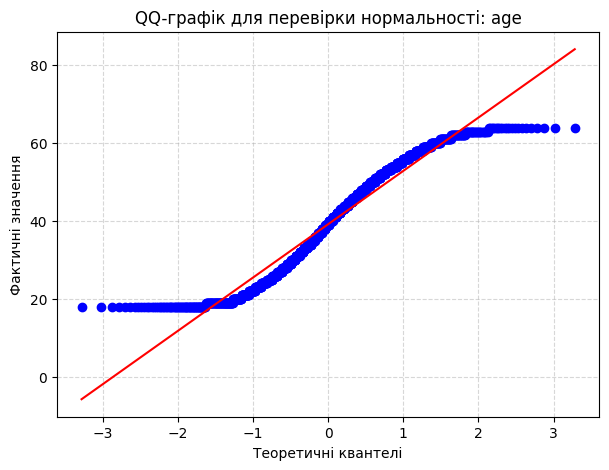

In [13]:
plot_qq(medical_df, 'age')

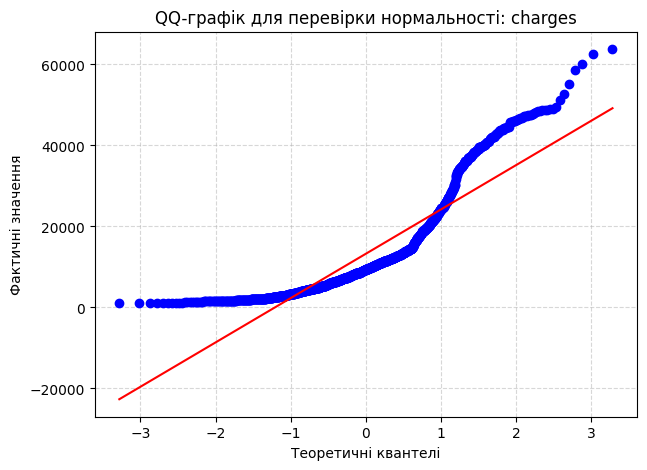

In [14]:
plot_qq(medical_df, 'charges')